# DATA 2402 Assignment 3

Importing required modules

In [22]:
from RaceSimulator import RaceSimulator, plot_tires, find_best_strategy
import pandas as pd
import numpy as np

## Test 1 - Creating a Sim object
**Expected** The sim object should be created, and it should match all of the parameters defined by assignment assumptions.

In [23]:
sim = RaceSimulator()

assert isinstance(sim.tires, pd.DataFrame)
assert list(sim.tires.index) == ["Soft", "Medium", "Hard"]
assert list(sim.tires.columns) == ["Tire", "Tmin", "Tmax", "alpha", "beta"]
assert sim.pit_time == 25
assert sim.max_laps == 60
assert sim.tires.loc["Soft", "Tmin"] == 0 and sim.tires.loc["Hard", "beta"] == 55

print("Initialization checks passed!")

Initialization checks passed!


## Test 2 - Tire Time Calculation

**Expected** We should get a time value of 0.005527786 for soft on age 0, (Excel rounds to 9 decimal places on our spreadsheet)  \
Medium on age 4 should have a time value of 1.046981131  \
Hard on age 25 should add 3.063713922
 



In [24]:
soft = sim.tires.loc['Soft']
medium = sim.tires.loc['Medium']
hard = sim.tires.loc['Hard']

print(sim.tire_time(4, hard['Tmin'], hard['Tmax'], hard['alpha'], hard['beta']))

assert(round(sim.tire_time(0, soft['Tmin'], soft['Tmax'], soft['alpha'], soft['beta']), 9) == 0.005527786)
assert(round(sim.tire_time(4, medium['Tmin'], medium['Tmax'], medium['alpha'], medium['beta']), 9) == 1.046981131)
assert(round(sim.tire_time(25, hard['Tmin'], hard['Tmax'], hard['alpha'], hard['beta']), 9) == 3.063713922)

print("Tire time calculation test passed")



2.31711071280776
Tire time calculation test passed


## Test 3 - Simualte Function

**Expected** Our spreadsheet gave us a value of 175.1202542 time added for the following strategy: ((15,23), (soft, medium, hard)). The simulate function should match that.


In [25]:
assert(sim.simulate([15,23], ["Soft", "Medium", "Hard"]))

## Test 4 - Plot Tires

**Expected** Given a simulator object, the plot tires function should generate a graph based on tire time.

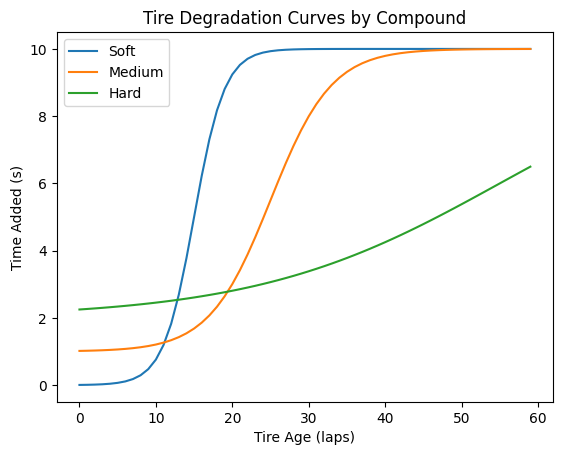

In [26]:
plot_tires(sim)

## Test 5 - Find Best Strategy

**Expected** The best strategy found, should return a time of 134.273016718482 according to the spreadsheet. Has to be rounded due to floating point rounding.


In [27]:
best = find_best_strategy(sim)
print(best)
assert(round(best[0], 12) == 134.273016718482)
print("Find Best Strategy test passed.")

Best strategy found (134.27s added)! Pitstops at laps: 16 and 38 using tire types: Soft then Medium then Medium.
(np.float64(134.27301671848213), ((16, 38), ('Soft', 'Medium', 'Medium')))
Find Best Strategy test passed.


## Test 6 Error - Invalid Strategy or input.

**Expected** Invalid Strategies should throw an exception so that they are ignored by the find_best_strategy function.


In [28]:
# Test 1: Fewer than 2 pitstops raises ValueError
raised = False
try:
    sim.simulate(pitstops=[15], tireTypes=["Soft", "Medium"])
except ValueError:
    raised = True
assert raised, "Expected ValueError when fewer than 2 pitstops are provided"

# Test 2: Pitstop exceeding max_laps raises ValueError
try:
    sim.simulate(pitstops=[15, sim.max_laps + 5], tireTypes=["Soft", "Medium", "Hard"])
    assert False, "Expected ValueError when pitstop exceeds max_laps"
except ValueError:
    pass

# Test 3: Invalid tire compound raises ValueError
try:
    sim.simulate(pitstops=[15, 23], tireTypes=["Soft", "SuperSoft", "Hard"])
    assert False, "Expected ValueError for invalid tire type"
except ValueError:
    pass

# Test 4: Fewer than 2 distinct tire types raises ValueError
try:
    sim.simulate(pitstops=[15, 23], tireTypes=["Soft", "Soft", "Soft"])
    assert False, "Expected ValueError when fewer than 2 distinct tires are used"
except ValueError:
    pass

print("All expected ValueError checks passed!")

All expected ValueError checks passed!


## Test 7 Special - Simulate Edge Cases

**Expected** When valid but unusual input is given to simulate (eg pitstop laps not in order) or pitting on the first and last lap. The function should still operate properly.

In [ ]:
# 1. Unsorted pitstops should still be handled cleanly and match sorted order
t_unsorted = sim.simulate(pitstops=[23, 15], tireTypes=["Soft", "Medium", "Hard"])
t_sorted = sim.simulate(pitstops=[15, 23], tireTypes=["Soft", "Medium", "Hard"])
assert np.isclose(t_unsorted, t_sorted), "Unsorted pitstops should yield the same total time"

# 2. Pitstop on the first and final lap (sim.max_laps)
t_final_lap_stop = sim.simulate(pitstops=[0, sim.max_laps], tireTypes=["Hard", "Soft", "Soft"]) #Best strategy ever!
print(f"Definitely an ideal strategy: {t_final_lap_stop}s added")
assert np.isfinite(t_final_lap_stop) and t_final_lap_stop > 0, "Pitstop on max_laps should be valid"

print("Special Cases passed!")

Definitely an ideal strategy: 494.99700380762636s added
Special Cases passed.
